# 3. Camera-Ready Analyses (ICCIT 2026)

Extra analyses added for the camera-ready version of the paper, in response to reviewer comments:

1. Signature statistics (how the duplication is distributed)
2. Train–test signature overlap under each protocol (a direct measure of leakage)
3. Fold-level leaky / honest results with mean ± s.d. and class-wise sensitivity / specificity
4. Temporal 80/20 split with sensitivity / specificity and a binomial test against the test-period majority
5. Repeated temporal evaluation over 10 random orderings of same-date records
6. Expanding-window temporal evaluation (train first 60/70/80/90%, test next 10%)
7. Deep models (TabNet, FT-Transformer), summarised from the author's GPU run (they can be retrained with a GPU)
8. Statistical tests (Wilcoxon, Spearman) and the final three-protocol figure with error bars

**Paper:** *Duplicate Feature Signatures Inflate Tabular Model Accuracy: A Leakage-Aware Re-Benchmark on Industrial Quality Data* (accepted for oral presentation at ICCIT 2026).

Run `01_leakage_diagnosis.ipynb` first (it creates `data/thesis_clean.csv`). Sensitivity / specificity treat **Bad** (the defect) as the positive class.

In [1]:
# Setup: clone the repo so relative paths work (skip if already running inside it, e.g. locally)
import os
if not os.path.exists('data/thesis_dataset.csv') and not os.path.exists('data/thesis_clean.csv'):
    !git clone -q https://github.com/Al-AminKhan043/leakage-aware-tabular-benchmark.git
    %cd leakage-aware-tabular-benchmark

In [2]:
# Safety net: install anything missing (Colab already has most of these; matters for local runs)
import importlib.util
_missing = [p for p in ["xgboost", "lightgbm", "scipy"] if importlib.util.find_spec(p) is None]
if _missing:
    %pip install -q {" ".join(_missing)}

## Load data, encode features, define the seven classical models

Identical to `02_benchmark.ipynb`: label-encoded categoricals, library defaults except RF (300 trees), MLP (64, 32), LogReg (max 1,000 iterations); seed 42.

In [3]:
import os, warnings
import numpy as np, pandas as pd
from scipy import stats
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings("ignore")

if not os.path.exists("data/thesis_clean.csv"):
    raise FileNotFoundError("data/thesis_clean.csv not found. Run 01_leakage_diagnosis.ipynb first "
                            "(raw data isn't in this repo; see data/README.md).")
df = pd.read_csv("data/thesis_clean.csv")
assert df["signature"].nunique() == 235
os.makedirs("results/tables", exist_ok=True); os.makedirs("results/figures", exist_ok=True)

feature_cols = [c for c in df.columns if c not in ["Date", "Quality", "signature"]]
df_enc = df.copy()
for c in feature_cols:
    if not pd.api.types.is_numeric_dtype(df_enc[c]):
        df_enc[c] = LabelEncoder().fit_transform(df_enc[c].astype(str))
le = LabelEncoder().fit(df["Quality"].astype(str))
df_enc["Quality"] = le.transform(df["Quality"].astype(str))
BAD = int(le.transform(["Bad"])[0])

X = df_enc[feature_cols]; y = df_enc["Quality"]; groups = df["signature"]
N = len(df)

models = {
    "LogReg":       make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "SVM":          make_pipeline(StandardScaler(), SVC(random_state=42)),
    "AdaBoost":     AdaBoostClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost":      XGBClassifier(random_state=42, n_jobs=-1, eval_metric="logloss"),
    "LightGBM":     LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
    "MLP":          make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)),
}

def scores(yt, p):
    yt, p = np.asarray(yt), np.asarray(p)
    return dict(acc=accuracy_score(yt, p), f1=f1_score(yt, p, average="macro"),
                sens=(p[yt == BAD] == BAD).mean(), spec=(p[yt != BAD] != BAD).mean())
print(df.shape, "| features:", len(feature_cols), "| Bad = class", BAD)

(9310, 15) | features: 12 | Bad = class 0


## 1. Signature statistics

A signature is the exact tuple of all 12 feature values (date and target excluded; numbers compared without rounding).

In [4]:
counts = df["signature"].value_counts()
labels_per_sig = df.groupby("signature")["Quality"].nunique()
mixed = labels_per_sig[labels_per_sig > 1].index
maj = df["Quality"].value_counts(normalize=True).max()
sig_major = df.groupby("signature")["Quality"].agg(lambda s: s.value_counts().index[0])
oracle = (df["Quality"] == df["signature"].map(sig_major)).mean()

print(f"Records: {N:,} | signatures: {len(counts)} | duplication: {1 - len(counts)/N:.2%}")
print(f"Records per signature: mean {counts.mean():.1f}, median {counts.median():.0f}, "
      f"IQR {counts.quantile(.25):.0f}-{counts.quantile(.75):.0f}, min {counts.min()}, max {counts.max()}, "
      f"singletons {(counts == 1).sum()}")
print(f"Mixed-label signatures: {len(mixed)} ({df['signature'].isin(mixed).sum():,} records)")
print(f"Majority baseline: {maj:.3f} | per-signature oracle ceiling: {oracle:.3f}")

Records: 9,310 | signatures: 235 | duplication: 97.48%
Records per signature: mean 39.6, median 31, IQR 30-31, min 1, max 211, singletons 4
Mixed-label signatures: 17 (1,339 records)
Majority baseline: 0.636 | per-signature oracle ceiling: 0.942


## 2. Train–test signature overlap

Share of test records whose exact signature also appears in the training set.

In [5]:
def overlap(tr, te):
    seen = set(groups.iloc[tr])
    return groups.iloc[te].isin(seen).mean()

ov_random = [overlap(tr, te) for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)]
ov_group  = [overlap(tr, te) for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, groups)]

dft = df.copy(); dft["dt"] = pd.to_datetime(dft["Date"], format="%m/%d/%Y", errors="coerce")
paper_order = dft.sort_values("dt").index.to_numpy()      # same ordering as 02_benchmark.ipynb
cut = int(N * 0.8)
ov_temporal = overlap(paper_order[:cut], paper_order[cut:])

print(f"Random 5-fold:  {np.mean(ov_random):.2%}  (min fold {np.min(ov_random):.2%})")
print(f"Grouped 5-fold: {np.mean(ov_group):.2%}")
print(f"Temporal 80/20: {ov_temporal:.2%}  (cut date {dft.loc[paper_order[cut], 'dt'].date()})")

Random 5-fold:  99.96%  (min fold 99.89%)
Grouped 5-fold: 0.00%
Temporal 80/20: 4.94%  (cut date 2023-05-26)


## 3. Fold-level leaky vs. honest results (mean ± s.d., sensitivity / specificity)

In [6]:
cv_rows = []
splits = {"leaky":  list(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)),
          "honest": list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, groups))}
for name, model in models.items():
    for proto, folds in splits.items():
        for k, (tr, te) in enumerate(folds):
            m = clone(model).fit(X.iloc[tr], y.iloc[tr])
            cv_rows.append(dict(model=name, protocol=proto, fold=k, **scores(y.iloc[te], m.predict(X.iloc[te]))))
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv("results/tables/cr_cv_folds.csv", index=False)

for proto in ["leaky", "honest"]:
    g = cv_df[cv_df.protocol == proto].groupby("model")
    t = pd.DataFrame({"acc_mean": g.acc.mean(), "acc_sd": g.acc.std(ddof=0),   # population s.d. over the 5 folds
                      "f1": g.f1.mean(), "sens": g.sens.mean(), "spec": g.spec.mean()})
    print(f"\n=== {proto.upper()} (5-fold) ===")
    print(t.sort_values("f1", ascending=False).round(3).to_string())


=== LEAKY (5-fold) ===
              acc_mean  acc_sd     f1   sens   spec
model                                              
LightGBM         0.936   0.006  0.929  0.881  0.967
XGBoost          0.935   0.005  0.929  0.882  0.965
RandomForest     0.934   0.006  0.928  0.882  0.964
MLP              0.876   0.016  0.858  0.716  0.968
LogReg           0.769   0.011  0.712  0.445  0.954
SVM              0.757   0.007  0.686  0.389  0.967
AdaBoost         0.703   0.017  0.573  0.211  0.984

=== HONEST (5-fold) ===
              acc_mean  acc_sd     f1   sens   spec
model                                              
RandomForest     0.771   0.063  0.740  0.603  0.866
XGBoost          0.765   0.067  0.737  0.612  0.852
MLP              0.768   0.049  0.724  0.505  0.917
LightGBM         0.755   0.050  0.714  0.531  0.882
LogReg           0.732   0.030  0.650  0.342  0.954
SVM              0.712   0.028  0.611  0.278  0.960
AdaBoost         0.666   0.021  0.537  0.207  0.929


## 4. Temporal 80/20 split (paper split) with binomial test

Train on the earliest 80% by date, test on the latest 20%. The binomial test compares each model's accuracy with the test-period majority rate.

In [7]:
Xs, ys = X.loc[paper_order], y.loc[paper_order]
Xtr, Xte, ytr, yte = Xs.iloc[:cut], Xs.iloc[cut:], ys.iloc[:cut], ys.iloc[cut:]
test_maj = max((yte == BAD).mean(), 1 - (yte == BAD).mean())
print(f"Test-period majority: {test_maj:.3f} (n = {len(yte)})\n")

t_rows = []
for name, model in models.items():
    p = clone(model).fit(Xtr, ytr).predict(Xte)
    s = scores(yte, p)
    s["binom_p"] = stats.binomtest(int((p == yte.values).sum()), len(yte), test_maj).pvalue
    t_rows.append(dict(model=name, **s))
temporal_single = pd.DataFrame(t_rows).sort_values("f1", ascending=False)
temporal_single.to_csv("results/tables/cr_temporal_8020.csv", index=False)
print(temporal_single.round(3).to_string(index=False))

Test-period majority: 0.635 (n = 1862)



       model   acc    f1  sens  spec  binom_p
RandomForest 0.704 0.680 0.591 0.768    0.000
         MLP 0.688 0.621 0.368 0.872    0.000
    LightGBM 0.640 0.603 0.458 0.744    0.718
     XGBoost 0.606 0.575 0.458 0.691    0.010
      LogReg 0.618 0.499 0.180 0.870    0.123
         SVM 0.653 0.470 0.090 0.975    0.129
    AdaBoost 0.537 0.378 0.044 0.819    0.000


## 5. Repeated temporal evaluation (10 orderings of same-date records)

About six records share each date, so the 80/20 cut depends on how ties are ordered. We shuffle records, then stable-sort by date, for 10 seeds. Models that ignore row order give zero spread.

In [8]:
def tie_order(seed):
    perm = np.random.RandomState(seed).permutation(N)
    return dft.iloc[perm].sort_values("dt", kind="stable").index.to_numpy()

ORDERS = [tie_order(s) for s in range(10)]
rep_rows = []
for name, model in models.items():
    for s, order in enumerate(ORDERS):
        tr, te = order[:cut], order[cut:]
        p = clone(model).fit(X.loc[tr], y.loc[tr]).predict(X.loc[te])
        rep_rows.append(dict(model=name, order=s, **scores(y.loc[te], p)))
rep_df = pd.DataFrame(rep_rows)
rep_df.to_csv("results/tables/cr_temporal_repeated.csv", index=False)
print(rep_df.groupby("model").agg(acc_mean=("acc", "mean"), acc_sd=("acc", "std"),   # sample s.d. over the 10 orderings
                                  acc_min=("acc", "min"), acc_max=("acc", "max"), f1=("f1", "mean"))
      .sort_values("acc_mean", ascending=False).round(3).to_string())

              acc_mean  acc_sd  acc_min  acc_max     f1
model                                                  
RandomForest     0.707   0.020    0.687    0.752  0.681
MLP              0.658   0.047    0.573    0.720  0.610
SVM              0.652   0.000    0.652    0.653  0.470
LightGBM         0.640   0.030    0.590    0.687  0.608
LogReg           0.618   0.000    0.618    0.618  0.499
XGBoost          0.615   0.022    0.574    0.656  0.582
AdaBoost         0.536   0.000    0.536    0.537  0.378


## 6. Expanding-window temporal evaluation

Train on the first 60 / 70 / 80 / 90% of records, test on the next 10%, for each of the 10 tie orderings (40 runs per model). Window majority rates differ a lot, so macro-F1 is the fairer summary.

In [9]:
exp_rows = []
for name, model in models.items():
    for s, order in enumerate(ORDERS):
        for c in [.6, .7, .8, .9]:
            a = int(N * c); b = int(N * (c + .1)) if c < .9 else N
            tr, te = order[:a], order[a:b]
            p = clone(model).fit(X.loc[tr], y.loc[tr]).predict(X.loc[te])
            exp_rows.append(dict(model=name, order=s, window=c, **scores(y.loc[te], p)))
exp_df = pd.DataFrame(exp_rows)
exp_df.to_csv("results/tables/cr_expanding.csv", index=False)
print("Window majority rates:", [round(max(y.loc[ORDERS[0][int(N*c):int(N*(c+.1)) if c < .9 else N]].mean(),
                                           1 - y.loc[ORDERS[0][int(N*c):int(N*(c+.1)) if c < .9 else N]].mean()), 2)
                                 for c in [.6, .7, .8, .9]])
print(exp_df.groupby("model").agg(acc_mean=("acc", "mean"), acc_sd=("acc", "std"),
                                  f1_mean=("f1", "mean"), f1_sd=("f1", "std"))
      .sort_values("f1_mean", ascending=False).round(3).to_string())

Window majority rates: [np.float64(0.79), np.float64(0.85), np.float64(0.61), np.float64(0.66)]
              acc_mean  acc_sd  f1_mean  f1_sd
model                                         
RandomForest     0.772   0.057    0.730  0.072
XGBoost          0.697   0.053    0.618  0.098
LightGBM         0.674   0.053    0.593  0.093
MLP              0.650   0.085    0.567  0.120
LogReg           0.699   0.097    0.566  0.073
SVM              0.693   0.067    0.543  0.114
AdaBoost         0.622   0.087    0.498  0.045


## 7. Deep models: TabNet and FT-Transformer (GPU)

Same analyses for the two deep models, using the same code as `analysis_deep.py`. **Switch the runtime to GPU** (`Runtime > Change runtime type > GPU`) and set `RUN_DEEP = True`. Each model is 5 folds × 2 CV protocols plus 5 temporal seeds plus 4 expanding windows × 5 seeds, at 100 epochs each, so expect a long run. Results are written row by row to `results/tables/deep_rows.csv`, so a rerun skips finished jobs.

With `RUN_DEEP = False` (the default) nothing is retrained: the cell below summarises `results/tables/deep_rows.csv`, the author's camera-ready run (AMD RX 9060 XT, ROCm, seeds 42/0/1/2/3), which is what the paper's Table III reports. Deep-model results move with the seed and with the GPU (up to 0.07 accuracy across hardware), so a fresh run will not match exactly.

In [10]:
RUN_DEEP = False      # set True on a GPU runtime
DEEP_SEEDS = [42, 0, 1, 2, 3]
EPOCHS = 100

if RUN_DEEP:
    import importlib.util, time
    for pkg, pipname in [("pytorch_tabnet", "pytorch-tabnet"), ("rtdl_revisiting_models", "rtdl_revisiting_models")]:
        if importlib.util.find_spec(pkg) is None:
            %pip install -q {pipname}
    import torch, torch.nn.functional as F
    from pytorch_tabnet.tab_model import TabNetClassifier
    from rtdl_revisiting_models import FTTransformer

    X_np = X.values.astype("float32"); y_np = y.values.astype("int64"); g_np = groups.values
    cat_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df[c])]
    cat_idxs = [feature_cols.index(c) for c in cat_cols]
    cat_dims = [int(df_enc[c].nunique()) for c in cat_cols]
    cont_idxs = [i for i in range(len(feature_cols)) if i not in cat_idxs]
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", device)

    def fit_tabnet(Xtr, ytr, Xte, seed=42):
        clf = TabNetClassifier(cat_idxs=cat_idxs, cat_dims=cat_dims, cat_emb_dim=1,
                               seed=seed, verbose=0, device_name="auto")
        clf.fit(Xtr, ytr, max_epochs=EPOCHS, patience=0, batch_size=256, virtual_batch_size=64)
        return clf.predict(Xte)

    def fit_ftt(Xtr, ytr, Xte, seed=42, lr=1e-3, batch_size=256):
        sc = StandardScaler().fit(Xtr[:, cont_idxs])
        tc = lambda A: torch.tensor(sc.transform(A[:, cont_idxs]), dtype=torch.float32, device=device)
        tk = lambda A: torch.tensor(A[:, cat_idxs], dtype=torch.long, device=device)
        Xtr_c, Xte_c, Xtr_k, Xte_k = tc(Xtr), tc(Xte), tk(Xtr), tk(Xte)
        yt = torch.tensor(ytr, dtype=torch.long, device=device)
        m = FTTransformer(n_cont_features=len(cont_idxs), cat_cardinalities=cat_dims,
                          d_out=2, **FTTransformer.get_default_kwargs()).to(device)
        opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-5)
        n = Xtr_c.shape[0]; m.train()
        for _ in range(EPOCHS):
            perm = torch.randperm(n, device=device)
            for i in range(0, n, batch_size):
                b = perm[i:i + batch_size]; opt.zero_grad()
                F.cross_entropy(m(Xtr_c[b], Xtr_k[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            return m(Xte_c, Xte_k).argmax(1).cpu().numpy()

    jobs = []
    for k, (tr, te) in enumerate(splits["leaky"]):  jobs.append(("leaky", k, tr, te, 42))
    for k, (tr, te) in enumerate(splits["honest"]): jobs.append(("honest", k, tr, te, 42))
    for sd in DEEP_SEEDS: jobs.append(("temporal8020", sd, paper_order[:cut], paper_order[cut:], sd))
    for c in [.6, .7, .8, .9]:
        a = int(N * c); b = int(N * (c + .1)) if c < .9 else N
        for sd in DEEP_SEEDS: jobs.append((f"expanding{c}", sd, paper_order[:a], paper_order[a:b], sd))

    ROWS = "results/tables/deep_rows.csv"
    done = set()
    if os.path.exists(ROWS):
        d = pd.read_csv(ROWS); done = set(zip(d.model, d.protocol, d.fold))
    for name, fit in [("TabNet", fit_tabnet), ("FT-Transformer", fit_ftt)]:
        for proto, k, tr, te, sd in jobs:
            if (name, proto, k) in done: continue
            torch.manual_seed(sd); np.random.seed(sd); t0 = time.time()
            p = fit(X_np[tr], y_np[tr], X_np[te], seed=sd); yt_ = y_np[te]
            row = dict(model=name, protocol=proto, fold=k, seed=sd, n=len(yt_), **scores(yt_, p),
                       secs=round(time.time() - t0, 1), device=device)
            pd.DataFrame([row]).to_csv(ROWS, mode="a", header=not os.path.exists(ROWS), index=False)
            print(f"{name:15s} {proto:13s} {k}  acc {row['acc']:.4f}  f1 {row['f1']:.4f}  ({row['secs']}s)")
    deep = pd.read_csv(ROWS)
    print(deep.groupby(["model", "protocol"])[["acc", "f1", "sens", "spec"]].mean().round(3))
else:
    print("RUN_DEEP = False: skipping deep-model training.")

# Summarise the deep-model runs. The repo ships results/tables/deep_rows.csv from the author's
# camera-ready run (AMD RX 9060 XT, ROCm; seeds 42,0,1,2,3); a new GPU run above overwrites/extends it.
ROWS = "results/tables/deep_rows.csv"
if os.path.exists(ROWS):
    deep = pd.read_csv(ROWS)
    deep["group"] = deep.protocol.str.replace(r"expanding.*", "expanding", regex=True)
    print(deep.groupby(["model", "group"]).agg(runs=("acc", "size"), acc_mean=("acc", "mean"), acc_sd=("acc", "std"),
                                              acc_min=("acc", "min"), acc_max=("acc", "max"), f1=("f1", "mean"),
                                              sens=("sens", "mean"), spec=("spec", "mean"))
          .round(3).to_string())
    near_zero = deep[(deep.group == "temporal8020") & (deep.pred_bad_frac < 0.05)]
    print("\nTemporal seeds that predict almost no defects (<5% predicted Bad):",
          near_zero[["model", "seed", "acc", "pred_bad_frac"]].round(3).to_string(index=False))
else:
    print("No deep_rows.csv found, so the paper's reported deep-model values are used below.")

RUN_DEEP = False: skipping deep-model training.
                             runs  acc_mean  acc_sd  acc_min  acc_max     f1   sens   spec
model          group                                                                      
FT-Transformer expanding       20     0.737   0.097    0.554    0.911  0.608  0.366  0.871
               honest           5     0.760   0.020    0.741    0.792  0.682  0.369  0.984
               leaky            5     0.827   0.009    0.818    0.838  0.793  0.577  0.971
               temporal8020     5     0.619   0.106    0.490    0.766  0.477  0.153  0.887
TabNet         expanding       20     0.753   0.112    0.503    0.932  0.670  0.531  0.818
               honest           5     0.677   0.046    0.624    0.727  0.635  0.479  0.790
               leaky            5     0.810   0.062    0.715    0.876  0.788  0.665  0.893
               temporal8020     5     0.773   0.068    0.699    0.833  0.742  0.639  0.850

Temporal seeds that predict almost no def

## 8. Statistical tests and final summary

Fold s.d. are population s.d. over the five folds; repeated-run s.d. are sample s.d. Wilcoxon signed-rank tests are paired across the nine models (with five folds, a fold-level test cannot reach p < 0.0625). Spearman's ρ compares the model rankings each protocol produces.

In [11]:
# classical models: computed above
leaky_acc  = cv_df[cv_df.protocol == "leaky"].groupby("model").acc.mean()
honest_acc = cv_df[cv_df.protocol == "honest"].groupby("model").acc.mean()
leaky_sd   = cv_df[cv_df.protocol == "leaky"].groupby("model").acc.std(ddof=0)
honest_sd  = cv_df[cv_df.protocol == "honest"].groupby("model").acc.std(ddof=0)
temp_acc   = rep_df.groupby("model").acc.mean()
temp_sd    = rep_df.groupby("model").acc.std()          # sample s.d., as in the paper

# deep models: Table II values (from results/tables/final_benchmark.csv) for leaky/honest
PAPER_DEEP = {  # leaky mean, leaky s.d., honest mean, honest s.d., temporal mean, temporal s.d. (as reported in the paper)
    "TabNet":         (.7872, .058, .7449, .043, .773, .068),   # from results/tables/final_benchmark.csv
    "FT-Transformer": (.8422, .007, .7317, .043, .619, .106),
}
for m_, (lm, ls, hm, hs, tm, ts) in PAPER_DEEP.items():
    leaky_acc[m_], leaky_sd[m_], honest_acc[m_], honest_sd[m_], temp_acc[m_], temp_sd[m_] = lm, ls, hm, hs, tm, ts
# Leaky/honest deep-model values stay at the primary benchmark (RTX 4060, Table II); the repeated
# temporal values come from deep_rows.csv. Deep-model CV accuracy moves across GPUs (TabNet honest
# 0.745 -> 0.677 on the second GPU), which is why the paper keeps the reviewed Table II numbers.
if os.path.exists("results/tables/deep_rows.csv"):
    deep = pd.read_csv("results/tables/deep_rows.csv")
    for m_ in ["TabNet", "FT-Transformer"]:
        v = deep[(deep.model == m_) & (deep.protocol == "temporal8020")].acc
        if len(v): temp_acc[m_], temp_sd[m_] = v.mean(), v.std()

summary = pd.DataFrame({"leaky": leaky_acc, "leaky_sd": leaky_sd, "honest": honest_acc, "honest_sd": honest_sd,
                        "temporal": temp_acc, "temporal_sd": temp_sd}).sort_values("honest", ascending=False)
summary.round(3).to_csv("results/tables/cr_summary.csv")
print(summary.round(3).to_string(), "\n")

def wil(a, b, label):
    d = summary[a] - summary[b]
    print(f"Wilcoxon {label}: {(d > 0).sum()}/9 models higher, p = {stats.wilcoxon(summary[a], summary[b]).pvalue:.4f}")
wil("leaky", "honest", "leaky > honest  ")
wil("honest", "temporal", "honest > temporal")
for a, b in [("leaky", "honest"), ("honest", "temporal"), ("leaky", "temporal")]:
    print(f"Spearman rho {a}-{b}: {stats.spearmanr(summary[a], summary[b]).correlation:.2f}")

                leaky  leaky_sd  honest  honest_sd  temporal  temporal_sd
model                                                                    
RandomForest    0.934     0.006   0.771      0.063     0.707        0.020
MLP             0.876     0.016   0.768      0.049     0.658        0.047
XGBoost         0.935     0.005   0.765      0.067     0.615        0.022
LightGBM        0.936     0.006   0.755      0.050     0.640        0.030
TabNet          0.787     0.058   0.745      0.043     0.773        0.068
LogReg          0.769     0.011   0.732      0.030     0.618        0.000
FT-Transformer  0.842     0.007   0.732      0.043     0.619        0.106
SVM             0.757     0.007   0.712      0.028     0.652        0.000
AdaBoost        0.703     0.017   0.666      0.021     0.536        0.000 

Wilcoxon leaky > honest  : 9/9 models higher, p = 0.0039
Wilcoxon honest > temporal: 8/9 models higher, p = 0.0078
Spearman rho leaky-honest: 0.80
Spearman rho honest-temporal: 0.48
Sp

## Figure: three protocols with error bars

±1 s.d. over folds (leaky, honest) or over repeated runs (temporal). Bars are ordered by honest accuracy.

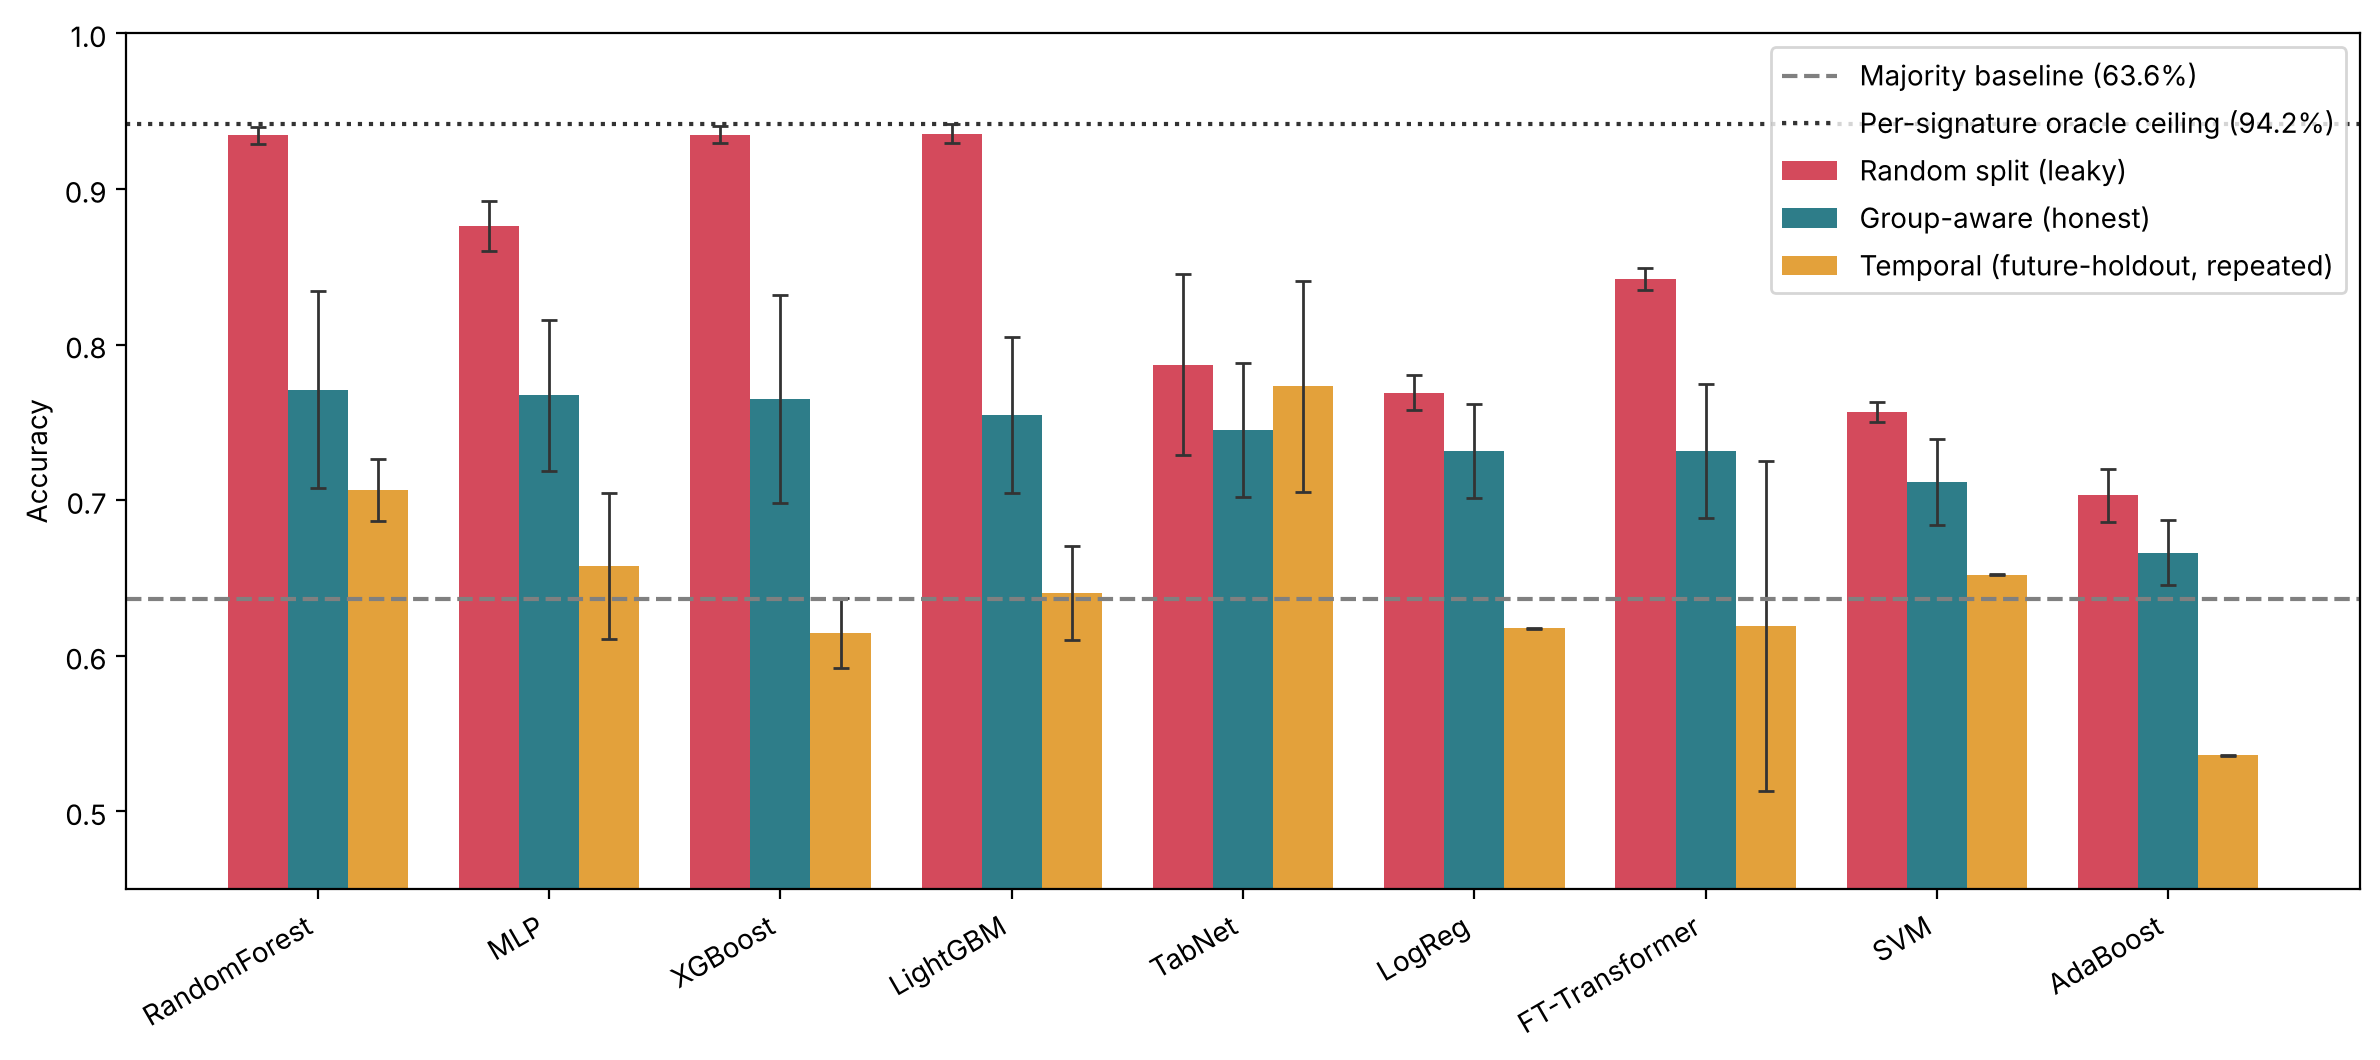

saved -> results/figures/three_protocol.png


In [12]:
import matplotlib.pyplot as plt
order = summary.index.tolist()
x = np.arange(len(order)); w = 0.26
fig, ax = plt.subplots(figsize=(12, 5.4))
ek = dict(ecolor="#333", capsize=3, elinewidth=1)
ax.bar(x - w, summary.leaky,    w, yerr=summary.leaky_sd,    color="#d44a5c", label="Random split (leaky)", error_kw=ek)
ax.bar(x,     summary.honest,   w, yerr=summary.honest_sd,   color="#2e7d89", label="Group-aware (honest)", error_kw=ek)
ax.bar(x + w, summary.temporal, w, yerr=summary.temporal_sd, color="#e3a13b", label="Temporal (future-holdout, repeated)", error_kw=ek)
ax.axhline(maj,    ls="--", color="gray", label=f"Majority baseline ({maj*100:.1f}%)")
ax.axhline(oracle, ls=":",  color="#333", label=f"Per-signature oracle ceiling ({oracle*100:.1f}%)")
ax.set_ylim(.45, 1.0); ax.set_ylabel("Accuracy")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha="right")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("results/figures/three_protocol.png", dpi=300, bbox_inches="tight")
plt.show()
print("saved -> results/figures/three_protocol.png")